# VaR of the hedged book

Notebook 05 measured the risk of the three APOs alone. A desk never holds them alone: the bot
of notebook 04 sells or buys futures against their deltas. This notebook puts the two together.

Same market, same 10 000 scenarios, same full revaluation as notebook 05. One thing added: the
**futures position of the bot**, whose P&L in a scenario is simply lots × lot size × price move.

1. The hedge: what the bot holds today
2. P&L of the book, of the hedge, and of both
3. VaR and ES, unhedged vs hedged
4. What is left once the delta is covered
5. Why the delta-normal VaR fails on a hedged book
6. From 1 day to 10 days: the square-root rule breaks
7. Limits

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Pricer, Quote, load_portfolio
from cmdty.hedging import load_hedge_settings, target_lots
from cmdty.market import any_exchange_calendar, contract_label
from cmdty.models.montecarlo import cholesky_factor
from cmdty.plotting import MUTED, SERIES, titles, use_style
from cmdty.risk import book_greeks, book_risk, book_theta

use_style()

start = MarketData(
    today=ql.Date(19, 11, 2026), rate=0.04,
    quotes={"HO": Quote(105.0, 0.30), "BRENT": Quote(75.0, 0.32), "WTI": Quote(71.0, 0.33)},
    correlations={("HO", "BRENT"): 0.95, ("WTI", "BRENT"): 0.97, ("HO", "WTI"): 0.93},
)
book = load_portfolio("../portfolios/example_book.yaml")
settings = load_hedge_settings("../config/hedging.yaml")
pricer = Pricer(model=settings.model, market=start)
today = book_risk(book, pricer)
underlyings = ["HO", "BRENT", "WTI"]

## 1. The hedge: what the bot holds today

The bot nets the deltas per **contract month** (each fixing is hedged in the future it fixes on),
then sells or buys whole lots against them. This is exactly what `HedgingBot` does on its first
day, called here directly.

In [2]:
lot = {u: settings.lot(u) for u in underlyings}
lots = target_lots(today.deltas_by_contract, lot)

hedge = pd.DataFrame([
    {"underlying": u, "contract": month, "option delta bbl": d,
     "futures lots": lots[(u, month)], "futures bbl": lots[(u, month)] * lot[u]}
    for (u, month), d in sorted(today.deltas_by_contract.items())
])
hedge.round(0)

,underlying,contract,option delta bbl,futures lots,futures bbl
0,BRENT,2027-03,-6881.0,7,7000.0
1,BRENT,2027-06,-7639.0,8,8000.0
2,BRENT,2027-08,9974.0,-10,-10000.0
3,HO,2027-07,-10398.0,10,10000.0
4,WTI,2027-05,4675.0,-5,-5000.0
5,WTI,2027-06,2671.0,-3,-3000.0


In [3]:
futures_bbl = hedge.groupby("underlying")["futures bbl"].sum()
residual = pd.DataFrame({
    "option delta bbl": pd.Series(today.deltas),
    "futures bbl": futures_bbl,
})
residual["residual delta bbl"] = residual.sum(axis=1)
residual.loc[underlyings].round(0)

,option delta bbl,futures bbl,residual delta bbl
HO,-10398.0,10000.0,-398.0
BRENT,-4547.0,5000.0,453.0
WTI,7346.0,-8000.0,-654.0


Per underlying, the futures cancel the options' delta to within one lot (1 000 bbl): what is
left is **lot rounding**. Brent shows the netting by contract: three positions of different signs,
one per month, that add up to the small net Brent delta.

## 2. P&L of the book, of the hedge, and of both

Same scenarios as notebook 05: same Cholesky factor, same seed, one business day, GBM.

In [4]:
calendar = any_exchange_calendar(["NYMEX", "ICE-EU"])
C = np.array([[start.corr(a, b) for b in underlyings] for a in underlyings])
L = cholesky_factor(C)
n = 10_000
X = np.random.default_rng(7).standard_normal((n, 3)) @ L.T


def year_fraction(start, horizon):
    """Business days from today to the horizon, over 252 a year."""
    return calendar.businessDaysBetween(start.today, horizon) / 252


def scenarios(x, start, horizon):
    """Prices of every underlying at the horizon, one row per scenario."""
    dt = year_fraction(start, horizon)
    vol = np.array([start.vol(u) for u in underlyings])
    f0 = np.array([start.forward(u) for u in underlyings])
    return pd.DataFrame(f0 * np.exp(-0.5 * vol**2 * dt + vol * np.sqrt(dt) * x), columns=underlyings)


def revalue(prices, start, horizon):
    """P&L of the options in each scenario: full revaluation on the horizon date."""
    rows = []
    for _, row in prices.iterrows():
        quotes = {u: Quote(row[u], start.vol(u)) for u in underlyings}
        p = pricer.with_market(start.model_copy(update={"today": horizon, "quotes": quotes}))
        rows.append(sum(t.instrument.quantity * p.pv(t.instrument) for t in book) - today.pv)
    return np.array(rows)


def hedge_pnl(moves):
    """P&L of the futures: bbl held times the price move (no premium, no discounting)."""
    return moves[underlyings].values @ futures_bbl.reindex(underlyings).fillna(0).values


tomorrow = calendar.advance(start.today, ql.Period(1, ql.Days))
prices = scenarios(X, start, tomorrow)
moves = prices - [start.forward(u) for u in underlyings]

pnl_options = revalue(prices, start, tomorrow)
pnl_futures = hedge_pnl(moves)
pnl_hedged = pnl_options + pnl_futures

## 3. VaR and ES, unhedged vs hedged

In [5]:
def var(p, level=0.99):
    return -np.quantile(p, 1 - level)


def es(p, level=0.99):
    return -p[p <= -var(p, level)].mean()


pd.DataFrame({
    "VaR 99% $": {"options alone": var(pnl_options), "futures alone": var(pnl_futures),
                  "options + futures": var(pnl_hedged)},
    "ES 99% $": {"options alone": es(pnl_options), "futures alone": es(pnl_futures),
                 "options + futures": es(pnl_hedged)},
}).round(0)

,VaR 99% $,ES 99% $
options alone,38433.0,43601.0
futures alone,36099.0,41734.0
options + futures,2624.0,3229.0


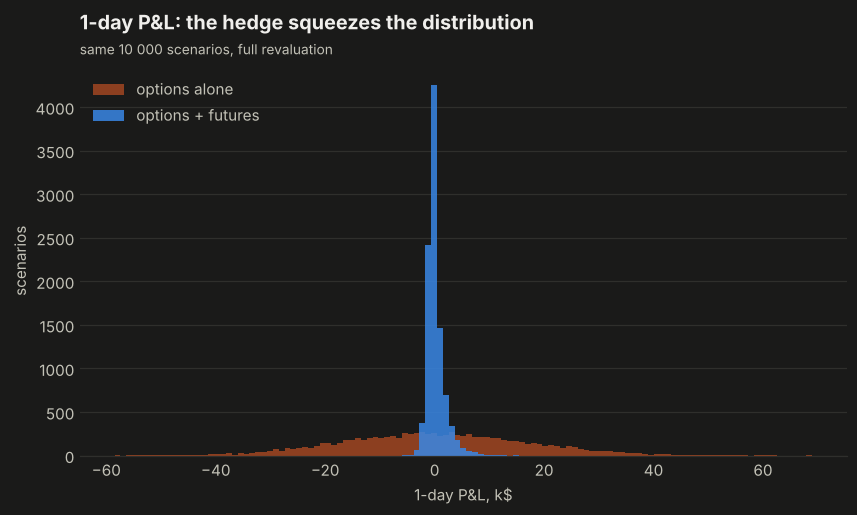

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.set_axisbelow(True)
bins = np.linspace(min(pnl_options.min(), pnl_hedged.min()), max(pnl_options.max(), pnl_hedged.max()), 120) / 1e3
ax.hist(pnl_options / 1e3, bins=bins, color=SERIES[1], alpha=0.6, label="options alone")
ax.hist(pnl_hedged / 1e3, bins=bins, color=SERIES[0], alpha=0.85, label="options + futures")
ax.set(xlabel="1-day P&L, k$", ylabel="scenarios")
ax.legend(loc="upper left", frameon=False)
titles(ax, "1-day P&L: the hedge squeezes the distribution", "same 10 000 scenarios, full revaluation")
plt.show()

The futures alone carry about as much risk as the options, in the opposite direction: added
together, they cancel most of it. The hedged distribution is a narrow spike. What sets its tail
is no longer the direction of the market.

## 4. What is left once the delta is covered

Split the hedged P&L with the greeks computed today:

$$
\text{P\&L}_{hedged} \approx
\underbrace{\sum_u (\Delta_u + h_u)\, dF_u}_{\text{residual delta (lot rounding)}}
+ \underbrace{\tfrac12 \sum_{a,b} \Gamma_{ab}\, dF_a\, dF_b}_{\text{gamma}}
+ \underbrace{\Theta}_{\text{one day}}
$$

with $h_u$ the futures held in bbl. Whatever the three terms miss is higher order.

In [7]:
greeks = book_greeks(book, pricer)
theta = book_theta(book, pricer, tomorrow)
res = residual["residual delta bbl"].reindex(underlyings).fillna(0).values

part_delta = moves.values @ res
part_gamma = np.array([greeks.gamma_pnl(dict(zip(underlyings, m))) for m in moves.values])
part_rest = pnl_hedged - part_delta - part_gamma - theta

tail = pnl_hedged <= -var(pnl_hedged)
pd.DataFrame({
    "std $": {"residual delta": part_delta.std(), "gamma": part_gamma.std(),
              "theta": 0.0, "rest": part_rest.std(), "hedged P&L": pnl_hedged.std()},
    "mean in the 1% worst $": {"residual delta": part_delta[tail].mean(),
                               "gamma": part_gamma[tail].mean(), "theta": theta,
                               "rest": part_rest[tail].mean(),
                               "hedged P&L": pnl_hedged[tail].mean()},
}).round(0)

,std $,mean in the 1% worst $
residual delta,1053.0,-1578.0
gamma,1169.0,-1338.0
theta,0.0,-348.0
rest,73.0,34.0
hedged P&L,1604.0,-3229.0


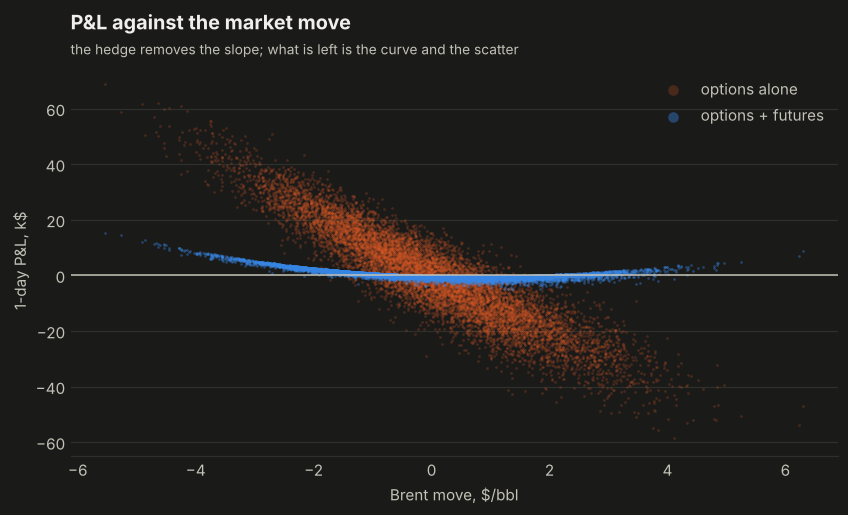

In [8]:
common = moves["BRENT"].values  # all prices move together: Brent stands for the market move
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.set_axisbelow(True)
ax.scatter(common, pnl_options / 1e3, s=3, alpha=0.25, color=SERIES[1], linewidths=0, label="options alone")
ax.scatter(common, pnl_hedged / 1e3, s=3, alpha=0.4, color=SERIES[0], linewidths=0, label="options + futures")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set(xlabel="Brent move, $/bbl", ylabel="1-day P&L, k$")
ax.legend(loc="upper right", frameon=False, markerscale=4)
titles(ax, "P&L against the market move", "the hedge removes the slope; what is left is the curve and the scatter")
plt.show()

Read the two clouds:

- **Options alone**: a steep slope. The P&L is mostly the delta: prices up, the book loses.
- **Options + futures**: the slope is gone, and what is left is a **smile**. When all prices move
  together, the book is slightly long gamma (the bought Brent put, see notebook 05): big moves
  in either direction *earn* a little. The bottom of the smile sits a bit right of zero: the
  residual delta from lot rounding is net short, so a small rise costs money, and the theta
  shifts the whole curve down.

So where does the hedged book lose in its 1% worst days? The table above says it: about half
**lot rounding** (residual delta) and half **gamma**, plus one day of theta. That gamma loss is
not on the common move, where the book is long gamma: it comes from the days when the legs
**diverge** (HO up, Brent down, correlation below 1). The spread then moves, and the book is
short the spread's curvature through the two sold crack options. A delta hedge per underlying
covers each leg, not the spread's convexity.

That is the honest answer to *"you hedged, so you have no risk?"*: the hedge covers the first
order. The rounding and the second order (gamma on the spread) stay, and they set the VaR.

## 5. Why the delta-normal VaR fails on a hedged book

The parametric VaR only sees deltas. On the hedged book the deltas are the residuals from
rounding. To see what it misses, add a second, ideal hedge: the exact deltas, no rounding to
whole lots. Its residual delta is zero, so its parametric VaR is only the theta:

$$
\text{VaR}_{99}^{\text{delta-normal}} = 2.33\,\sqrt{h^\top \Sigma\, h}, \qquad h = \text{residual deltas}
$$

In [9]:
dt = year_fraction(start, tomorrow)
sd = np.array([start.forward(u) * start.vol(u) * np.sqrt(dt) for u in underlyings])
cov = np.outer(sd, sd) * C


def parametric(residual_delta):
    return 2.326 * np.sqrt(residual_delta @ cov @ residual_delta) - theta


delta = np.array([today.deltas[u] for u in underlyings])
pnl_exact = pnl_options - moves.values @ delta  # futures = exactly minus the delta

pd.DataFrame({
    "hedge in lots (the bot)": {
        "full revaluation": var(pnl_hedged),
        "delta-gamma": var(part_delta + part_gamma + theta),
        "delta-normal (parametric)": parametric(res),
    },
    "exact hedge (no rounding)": {
        "full revaluation": var(pnl_exact),
        "delta-gamma": var(part_gamma + theta),
        "delta-normal (parametric)": parametric(np.zeros(3)),
    },
}).round(0)

,hedge in lots (the bot),exact hedge (no rounding)
full revaluation,2624.0,1658.0
delta-gamma,2652.0,1670.0
delta-normal (parametric),2824.0,348.0


- **Hedge in lots**: the parametric VaR lands close, but by luck. It sees the rounding residual
  and nothing of the gamma; here the two happen to be of the same size.
- **Exact hedge**: the delta is zero, so the parametric VaR reports only one day of theta, a few
  hundred dollars. The full revaluation still finds the gamma on the spread. The linear method
  says "no risk" exactly where the risk is all second order.

On the unhedged book (notebook 05) all methods agreed, because the delta dominated. Once the
delta is hedged, what is left is the part a linear method cannot see. This is why a risk system
revalues in full, or at least adds the gamma, as soon as the book holds options.

## 6. From 1 day to 10 days: the square-root rule breaks

Hold the same hedge for 10 business days (no rebalancing) and compare with 1-day VaR $\times\sqrt{10}$.

In [10]:
horizon10 = calendar.advance(start.today, ql.Period(10, ql.Days))
prices10 = scenarios(X, start, horizon10)
moves10 = prices10 - [start.forward(u) for u in underlyings]
pnl_options10 = revalue(prices10, start, horizon10)
pnl_hedged10 = pnl_options10 + hedge_pnl(moves10)

pd.DataFrame({
    "1 day": {"options alone": var(pnl_options), "options + futures": var(pnl_hedged)},
    "1 day x sqrt(10)": {"options alone": var(pnl_options) * np.sqrt(10),
                         "options + futures": var(pnl_hedged) * np.sqrt(10)},
    f"10 days (to {horizon10.ISO()})": {"options alone": var(pnl_options10),
                                        "options + futures": var(pnl_hedged10)},
}).round(0)

,1 day,1 day x sqrt(10),10 days (to 2026-12-03)
options alone,38433.0,121537.0,118535.0
options + futures,2624.0,8299.0,19973.0


- **Options alone**: the rule works, because the delta P&L grows like $\sqrt{t}$.
- **Hedged book**: the direct 10-day VaR is more than twice the scaled one. The gamma P&L is
  proportional to $dF^2$, so it grows like $t$, not $\sqrt{t}$; the theta also grows like $t$.
  Scaling the 1-day number by $\sqrt{10}$ badly understates the risk of a delta-hedged
  options book.
- And a 10-day static hedge is pessimistic: the bot rebalances every day, so over ten days it
  would re-centre its delta as prices move.

## 7. Limits

- **One forward per underlying**: the futures of each month move with the same price, so the
  hedge per contract month looks perfect across months. With a real curve, a Jan Brent hedge
  against an April Brent delta would leave **basis risk** between the two months. This is the
  next big step (futures curve in the roadmap).
- **Vols do not move**: the hedge covers delta only, and the vega is unhedged; with vols as risk
  factors it would show up here.
- **Static over the horizon**: no rebalancing inside the 10 days, no transaction costs.
- **Normal shocks** and implied vols, as in notebook 05.